In [38]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [39]:
class Batsman_state(TypedDict):
    runs:int
    balls:int
    fours:int
    sixes:int
    sr:float
    summary:str
    bpb:float
    boundary_percent:float

In [40]:
def calculateSR(state:Batsman_state) -> dict:
    sr=(state['runs']/state['balls'])*100
    return {'sr':sr}

In [41]:
def calculateBPB(state:Batsman_state)->dict:
    bpb=state['balls']/(state['fours']+state['sixes'])
    return {'bpb':bpb}

In [42]:
def calculateBoundaryRate(state: Batsman_state)->dict:
    boundaryRate=(((state['fours']*4) + (state['sixes']*6))/state['runs'])*100
    return {'boundary_percent':boundaryRate}

In [43]:
def calculateSummary(state:Batsman_state) -> dict:
    summary=f"""
     Strike Rate - {state['sr']} 
     Boundary Per Ball - {state['bpb']} 
     Boundary Percent - {state['boundary_percent']} 
    """
    return {'summary':summary}

In [44]:
graph =StateGraph(Batsman_state)

graph.add_node("SR",calculateSR)
graph.add_node("bpb",calculateBPB)
graph.add_node("boundary_percent",calculateBoundaryRate)
graph.add_node("summary",calculateSummary)

graph.add_edge(START,'SR')
graph.add_edge(START,'bpb')
graph.add_edge(START,'boundary_percent')

graph.add_edge('SR','summary')
graph.add_edge('bpb','summary')
graph.add_edge('boundary_percent','summary')

graph.add_edge('summary',END)

In [45]:
workflow=graph.compile()

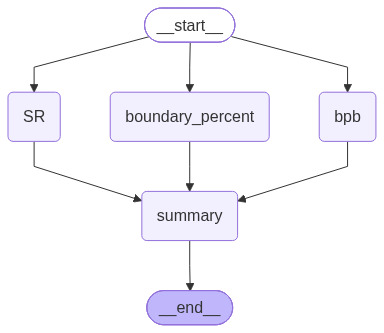

In [46]:
workflow

In [47]:
initial_state={
    'runs':100,
    'balls':50,
    'fours':5,
    'sixes':6
}

workflow.invoke(initial_state)

{'runs': 100,
 'balls': 50,
 'fours': 5,
 'sixes': 6,
 'sr': 200.0,
 'summary': '\n     Strike Rate - 200.0 \n     Boundary Per Ball - 4.545454545454546 \n     Boundary Percent - 56.00000000000001 \n    ',
 'bpb': 4.545454545454546,
 'boundary_percent': 56.00000000000001}